# 03 — Exploratory Data Analysis

**Stage 3 of the Tier A pipeline** (`DOCS/STRUCTURE.md`). Hypothesis-driven, one section per branch
of the Stage 0 issue tree. Every chart carries an **Action Title** and a written **So What** and
**Implication** beneath it. No orphan charts.

> **The discipline that makes this notebook different.** Every bivariate view is produced **twice** —
> once at row level (252,000 rows) and once at profile level (42,007 applicants). *The gap between
> the two panels is the finding*, and it repeats in every branch.

| Branch | Question |
|---|---|
| **A. Instrument integrity** | Is a row an observation? Does file position leak? Do train and test speak the same language? |
| **B. Applicant demographics** | Do Age, marital status, Income separate defaulters? |
| **C. Employment & tenure** | Does Profession, Experience or job tenure separate them? |
| **D. Residential & assets** | Does home or car ownership? |
| **E. Geography** | Does CITY or STATE? |
| **F. Identification** | Which unit of analysis is the honest one? |

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

ROOT = Path.cwd()
while not (ROOT / "archive" / "Training Data.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROC, REPORTS, FIGS = ROOT / "data" / "processed", ROOT / "reports", ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------------------------------
# DESIGN.md palette, defined inline (no local module imports — a fresh clone must run as-is).
#
# Validated with the dataviz skill's checker rather than eyeballed:
#   node scripts/validate_palette.js "#2251FF,#00857C,#C1841C" --mode light
#     PASS lightness | PASS CVD separation (worst adjacent dE 13.2 protan)
#     PASS normal-vision separation (21.8) | PASS contrast vs surface
# The five-slot DESIGN.md order FAILS on the Cyan-Slate adjacent pair (normal-vision dE 12.9,
# below the hard floor of 15), so Cyan and Slate are NOT used as categorical identities here.
# Grey is context ink only; Navy is text ink only; neither is ever a series colour.
# ---------------------------------------------------------------------------------------------
NAVY, BLUE, TEAL, AMBER = "#051C2C", "#2251FF", "#00857C", "#C1841C"
SLATE, GREY, GRID = "#7F93A6", "#9FADB8", "#E9ECEF"

# Semantic mapping, fixed once and used in every notebook:
C_HONEST = BLUE       # profile level / grouped / singleton block — the emphasis story
C_OPTIMISTIC = TEAL   # row level / as delivered — the number that flatters
C_REFERENCE = AMBER   # base rate, chance line, thresholds, the contrasting block
C_CONTEXT = GREY      # non-highlighted context, never an identity


def apply_style():
    mpl.rcParams.update({
        "figure.dpi": 130, "savefig.dpi": 130, "figure.facecolor": "white",
        "axes.facecolor": "white", "savefig.facecolor": "white",
        "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 9, "text.color": NAVY,
        "axes.titlelocation": "left", "axes.titlesize": 10.5, "axes.titleweight": "bold",
        "axes.titlecolor": NAVY, "axes.titlepad": 10,
        "axes.labelsize": 9, "axes.labelcolor": SLATE, "axes.edgecolor": GREY,
        "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
        "xtick.color": SLATE, "ytick.color": SLATE, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
        "grid.color": GRID, "grid.linewidth": 0.8, "axes.grid": True, "axes.grid.axis": "y",
        "axes.axisbelow": True,          # grid behind the marks, never through them
        "legend.frameon": False, "legend.fontsize": 8.5,
        "lines.linewidth": 2.0, "lines.markersize": 8,
    })


apply_style()
PCT = PercentFormatter(1.0)


def finish(ax, source, note=""):
    """Every exhibit carries its source line — STRUCTURE.md Step 7.3."""
    ax.figure.text(0.005, -0.02, f"Source: {source}" + (f" · {note}" if note else ""),
                   fontsize=7, color=SLATE, ha="left", va="top", transform=ax.figure.transFigure)


def save(fig, name):
    fig.savefig(FIGS / name, bbox_inches="tight", facecolor="white")
    print(f"  saved reports/figures/{name}")


rows = pd.read_parquet(PROC / "loan_rows.parquet")
profiles = pd.read_parquet(PROC / "loan_profiles.parquet")
singles = pd.read_parquet(PROC / "loan_singletons.parquet")
test = pd.read_parquet(PROC / "test_reconciled.parquet")
kf = json.loads((REPORTS / "_key_figures.json").read_text())

TARGET = "Risk_Flag"
NUMERIC = ["Income", "Age", "Experience", "CURRENT_JOB_YRS", "CURRENT_HOUSE_YRS"]
LOWCARD = ["Married/Single", "House_Ownership", "Car_Ownership"]
HIGHCARD = ["Profession", "STATE", "CITY"]
BASE = rows[TARGET].mean()

print(f"rows      {len(rows):>7,}  positive rate {rows[TARGET].mean():.4f}")
print(f"profiles  {len(profiles):>7,}  positive rate {profiles[TARGET].mean():.4f}")
print(f"singles   {len(singles):>7,}  positive rate {singles[TARGET].mean():.4f}")
print(f"test      {len(test):>7,}")

rows      252,000  positive rate 0.1230
profiles   42,007  positive rate 0.1909
singles    36,007  positive rate 0.2016
test       28,000


## 3.1 Branch A — instrument integrity

### Exhibit 1 — This file has 42,007 applicants, not 252,000: six thousand of them appear 27 to 40 times each

  saved reports/figures/ex01_replication.png


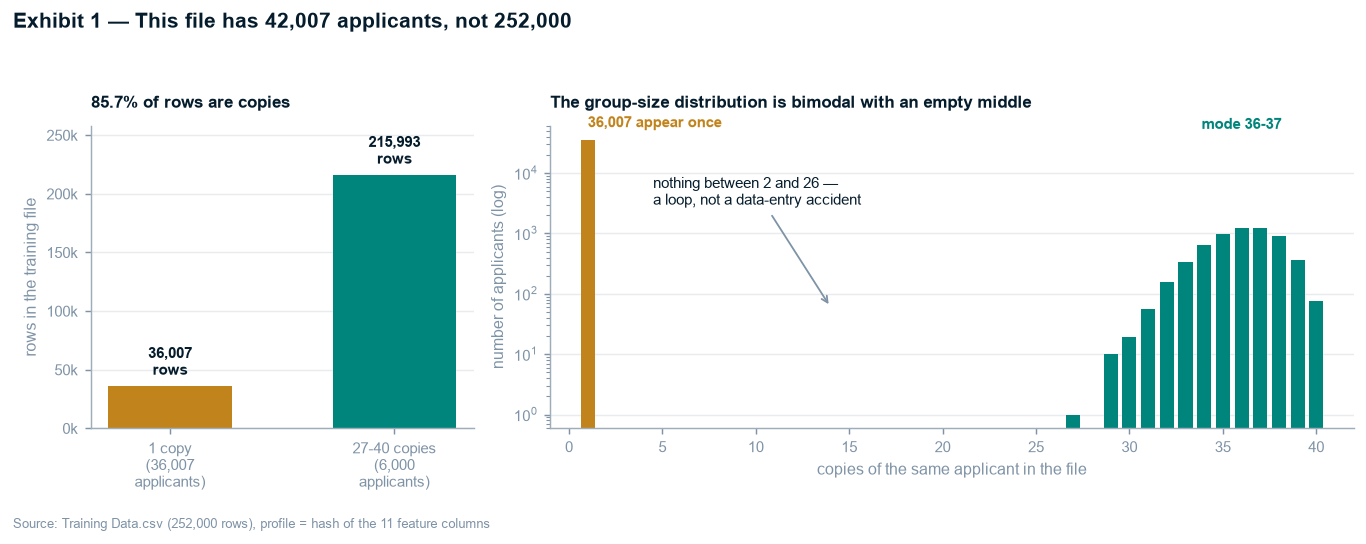

In [2]:
gs = rows.groupby("profile_id").size().value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1, 2.1]})

ax1.bar(["1 copy\n(36,007\napplicants)", "27-40 copies\n(6,000\napplicants)"],
        [36007, 215993], color=[C_REFERENCE, C_OPTIMISTIC], width=0.55)
for i, v in enumerate([36007, 215993]):
    ax1.text(i, v + 6000, f"{v:,}\nrows", ha="center", va="bottom", fontsize=8.5,
             color=NAVY, fontweight="bold")
ax1.set_ylim(0, 258000)
ax1.set_ylabel("rows in the training file")
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v/1000:.0f}k"))
ax1.set_title("85.7% of rows are copies", fontsize=9.5)

ax2.bar(gs.index, gs.values, color=C_OPTIMISTIC, width=0.75)
ax2.bar([1], [gs.loc[1]], color=C_REFERENCE, width=0.75)
ax2.set_yscale("log")
ax2.set_xlabel("copies of the same applicant in the file")
ax2.set_ylabel("number of applicants (log)")
ax2.set_xlim(-1, 42)
ax2.annotate("nothing between 2 and 26 —\na loop, not a data-entry accident",
             xy=(14, 60), xytext=(4.5, 3000), fontsize=8.5, color=NAVY,
             arrowprops=dict(arrowstyle="->", color=SLATE, lw=1))
ax2.text(1, gs.loc[1] * 1.6, "36,007 appear once", fontsize=8.5, color=C_REFERENCE, fontweight="bold")
ax2.text(36, gs.max() * 1.5, "mode 36-37", fontsize=8.5, color=C_OPTIMISTIC,
         fontweight="bold", ha="center")
ax2.set_title("The group-size distribution is bimodal with an empty middle", fontsize=9.5)

fig.suptitle("Exhibit 1 — This file has 42,007 applicants, not 252,000",
             x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=1.06)
finish(ax2, "Training Data.csv (252,000 rows), profile = hash of the 11 feature columns")
plt.tight_layout()
save(fig, "ex01_replication.png")
plt.show()

**So What:** A random 5-fold split places copies of the same applicant in the training fold and the
validation fold. The model is then scored on rows it has already seen, and the reported metric
measures memorisation rather than generalisation.

**Implication:** every split, statistical test and permutation in this project uses `profile_id` as
the unit of independence. Notebook `05` measures what ignoring that is worth.

### Exhibit 6 — The file is sorted into two blocks whose applicants are identical and whose default rates are not

  saved reports/figures/ex06_file_order.png


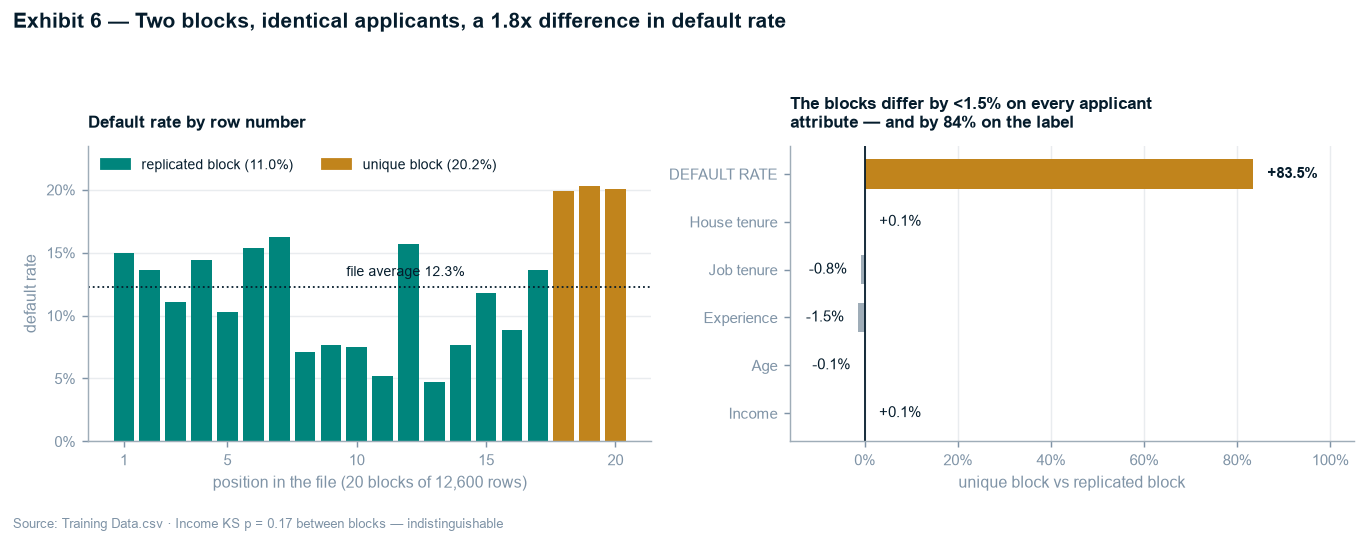

                    rows  default_rate
block                                 
replicated_block  215993        0.1099
unique_block       36007        0.2016


In [3]:
nb = 20
pos_block = pd.DataFrame({
    "block": np.arange(len(rows)) // (len(rows) // nb),
    "y": rows[TARGET].to_numpy(),
    "single": (rows.block == "unique_block").to_numpy(),
}).groupby("block").agg(rate=("y", "mean"), single=("single", "mean"))
pos_block = pos_block.iloc[:nb]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.6))

x = np.arange(nb)
cols = [C_REFERENCE if s > .5 else C_OPTIMISTIC for s in pos_block.single]
ax1.bar(x, pos_block.rate, color=cols, width=0.8)
ax1.axhline(BASE, color=NAVY, lw=1, ls=":")
ax1.text(8.6, BASE + .006, f"file average {BASE:.1%}", fontsize=8, color=NAVY, ha="left", va="bottom")
ax1.set_xticks([0, 4, 9, 14, 19], ["1", "5", "10", "15", "20"])
ax1.set_xlabel("position in the file (20 blocks of 12,600 rows)")
ax1.set_ylabel("default rate")
ax1.set_ylim(0, 0.235)
ax1.yaxis.set_major_formatter(PCT)
ax1.set_title("Default rate by row number", fontsize=9.5)
ax1.legend(handles=[mpl.patches.Patch(color=C_OPTIMISTIC, label="replicated block (11.0%)"),
                    mpl.patches.Patch(color=C_REFERENCE, label="unique block (20.2%)")],
           loc="upper left", fontsize=8, ncol=2)

# One axis, one unit: how far apart are the two blocks on each quantity, in percent?
blk = rows.groupby("block")[NUMERIC].mean()
diffs = [(blk.loc["unique_block", c] / blk.loc["replicated_block", c] - 1) for c in NUMERIC]
rate_rep = rows.loc[rows.block == "replicated_block", TARGET].mean()
rate_uni = rows.loc[rows.block == "unique_block", TARGET].mean()
diffs.append(rate_uni / rate_rep - 1)
labels = ["Income", "Age", "Experience", "Job tenure", "House tenure", "DEFAULT RATE"]
colr = [C_CONTEXT] * 5 + [C_REFERENCE]

yy = np.arange(6)
ax2.barh(yy, diffs, color=colr, height=0.62)
ax2.axvline(0, color=NAVY, lw=1)
for i, v in enumerate(diffs):
    ax2.text(v + (0.03 if v >= 0 else -0.03), i, f"{v:+.1%}", va="center",
             ha="left" if v >= 0 else "right", fontsize=8.5, color=NAVY,
             fontweight="bold" if i == 5 else "normal")
ax2.set_yticks(yy, labels, fontsize=8.5)
ax2.set_xlim(-0.16, 1.05)
ax2.xaxis.set_major_formatter(PCT)
ax2.set_xlabel("unique block vs replicated block")
ax2.grid(axis="x"); ax2.grid(axis="y", visible=False)
ax2.set_title("The blocks differ by <1.5% on every applicant\nattribute — and by 84% on the label",
              fontsize=9.5)

fig.suptitle("Exhibit 6 — Two blocks, identical applicants, a 1.8x difference in default rate",
             x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=1.06)
finish(ax2, "Training Data.csv", "Income KS p = 0.17 between blocks — indistinguishable")
plt.tight_layout()
save(fig, "ex06_file_order.png")
plt.show()

print(rows.groupby("block").agg(rows=(TARGET, "size"), default_rate=(TARGET, "mean")).round(4).to_string())

**So What:** the label rate depends on where a row sits in the file, and nothing about the applicant
predicts which side of the boundary they landed on. `ID` therefore carries real signal (AUC 0.674,
audit A-02) while the eleven genuine features carry none.

**Implication:** `ID` and `block` are barred from every model. The two blocks are also the reason a
clean sub-sample exists — `loan_singletons` — where a plain `StratifiedKFold` is legitimate.

### Exhibits 3 and 4 — Half the test set arrives in a vocabulary the training file never uses, and that hides an 86% overlap

  saved reports/figures/ex03_04_vocabulary_overlap.png


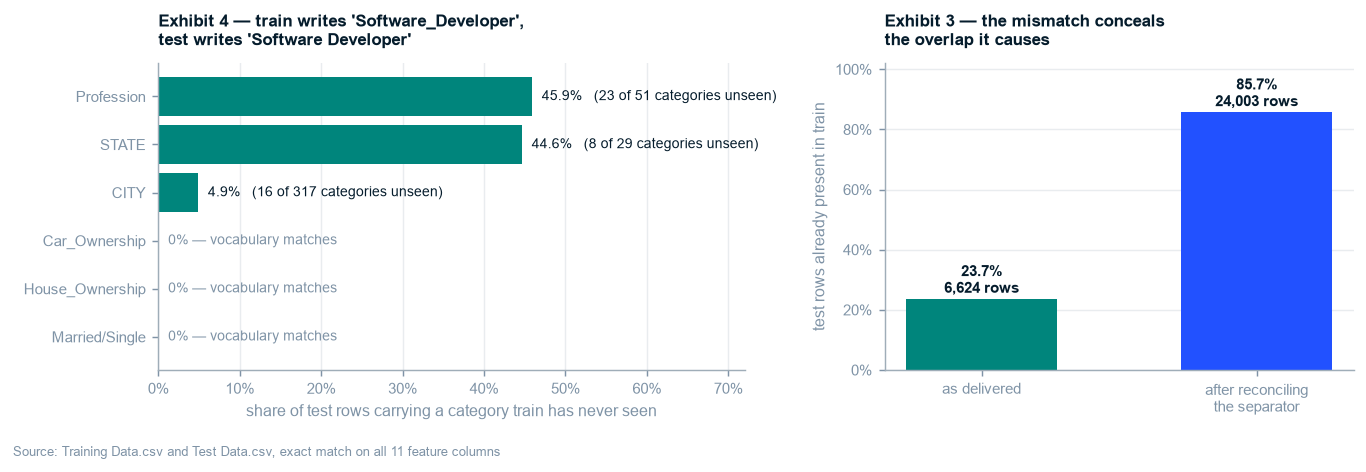

In [4]:
vc = pd.read_csv(PROC / "_vocabulary_check.csv")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.4), gridspec_kw={"width_ratios": [1.25, 1]})

vc = vc.sort_values("test_rows_unseen_pct").reset_index(drop=True)
ax1.barh(vc.column, vc.test_rows_unseen_pct,
         color=[C_CONTEXT if v == 0 else C_OPTIMISTIC for v in vc.test_rows_unseen_pct])
for y, row in vc.iterrows():
    if row.test_rows_unseen_pct == 0:
        ax1.text(0.012, y, "0% — vocabulary matches", va="center", fontsize=8, color=SLATE)
    else:
        ax1.text(row.test_rows_unseen_pct + .012, y,
                 f"{row.test_rows_unseen_pct:.1%}   "
                 f"({row.test_only_categories} of {row.train_categories} categories unseen)",
                 va="center", fontsize=8, color=NAVY)
ax1.xaxis.set_major_formatter(PCT)
ax1.set_xlim(0, 0.72)
ax1.set_xlabel("share of test rows carrying a category train has never seen")
ax1.grid(axis="x"); ax1.grid(axis="y", visible=False)
ax1.set_title("Exhibit 4 — train writes 'Software_Developer',\ntest writes 'Software Developer'", fontsize=9.5)

vals = [kf["test_overlap_raw"] / 28000, kf["test_overlap_normalised"] / 28000]
ax2.bar(["as delivered", "after reconciling\nthe separator"], vals,
        color=[C_OPTIMISTIC, C_HONEST], width=0.55)
for i, v in enumerate(vals):
    ax2.text(i, v + .02, f"{v:.1%}\n{int(v*28000):,} rows", ha="center", fontsize=8.5,
             color=NAVY, fontweight="bold")
ax2.set_ylim(0, 1.02)
ax2.yaxis.set_major_formatter(PCT)
ax2.set_ylabel("test rows already present in train")
ax2.set_title("Exhibit 3 — the mismatch conceals\nthe overlap it causes", fontsize=9.5)

finish(ax2, "Training Data.csv and Test Data.csv, exact match on all 11 feature columns")
plt.tight_layout()
save(fig, "ex03_04_vocabulary_overlap.png")
plt.show()

**So What:** two defects compound. An encoder fitted on train silently maps 72% of test rows to
"unknown"; and because the vocabularies differ, the analyst who checks whether the holdout is
genuinely held out gets back **23%** instead of the true **86%**.

**Implication:** the reconciliation in notebook `02` is a prerequisite for measuring anything about
the test set at all — and once measured, the test set turns out to be unusable as a holdout.

## 3.2 Branches B, C, D — demographics, employment, assets

The brief (§5B) asks for risk rate by ownership, marital status, age band and income quartile. Here
they are — computed at row level, the way they are usually computed, and at profile level beside them.

In [5]:
def rate_table(col):
    r = rows.groupby(col, observed=True)[TARGET].agg(rows="size", row_rate="mean")
    p = profiles.groupby(col, observed=True)[TARGET].agg(applicants="size", profile_rate="mean")
    t = r.join(p)
    t["row_lift"] = t.row_rate / rows[TARGET].mean()
    t["profile_lift"] = t.profile_rate / profiles[TARGET].mean()
    return t.round(4)


for c in LOWCARD + ["Age_Band", "Income_Quartile"]:
    print(f"\n--- {c} ---")
    print(rate_table(c).to_string())


--- Married/Single ---
                  rows  row_rate  applicants  profile_rate  row_lift  profile_lift
Married/Single                                                                    
married          25728    0.1025        4241        0.1853     0.833        0.9706
single          226272    0.1253       37766        0.1916     1.019        1.0033

--- House_Ownership ---
                   rows  row_rate  applicants  profile_rate  row_lift  profile_lift
House_Ownership                                                                    
norent_noown       7184    0.0995        1243        0.1995    0.8092        1.0449
owned             12918    0.0898        2187        0.1811    0.7301        0.9483
rented           231898    0.1256       38577        0.1912    1.0209        1.0015

--- Car_Ownership ---
                 rows  row_rate  applicants  profile_rate  row_lift  profile_lift
Car_Ownership                                                                    
no          

  saved reports/figures/fig_univariate_lifts.png


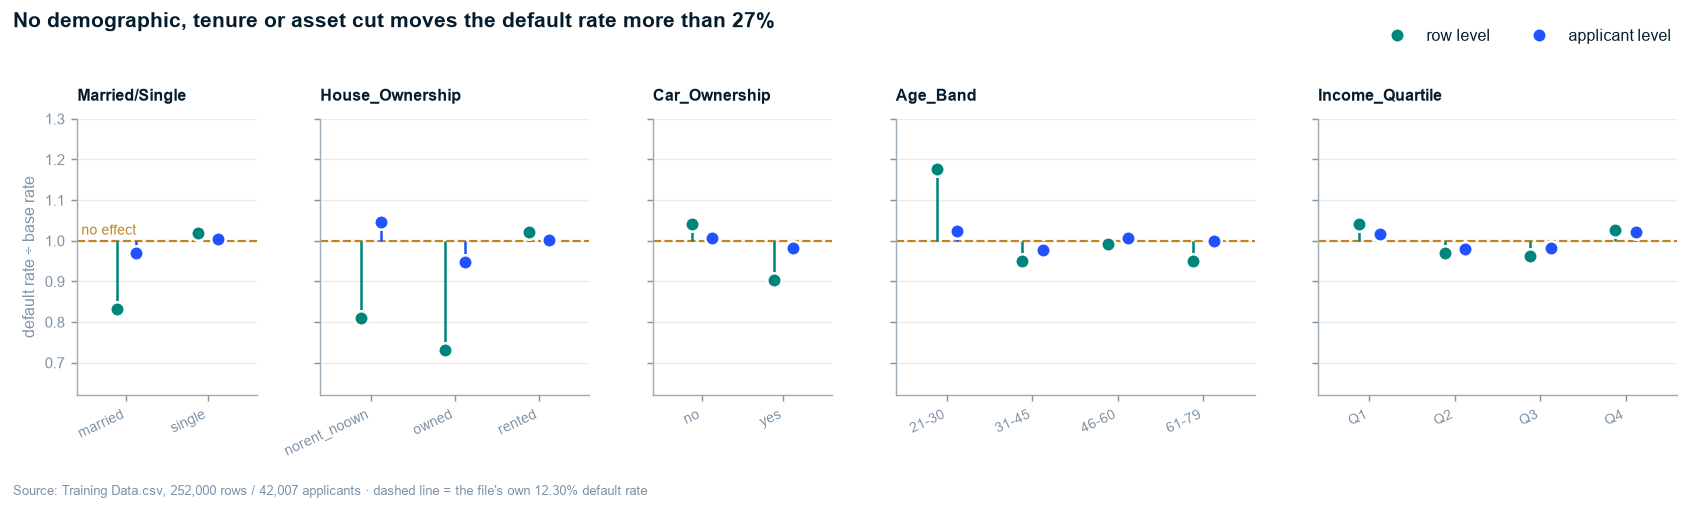

In [6]:
# A lift is a ratio around 1.0, so it is drawn as dots against a reference line — bars would
# either need a zero baseline (wasting the whole plot) or a truncated one (an anti-pattern).
fig, axes = plt.subplots(1, 5, figsize=(13, 3.4), sharey=True,
                         gridspec_kw={"width_ratios": [2, 3, 2, 4, 4]})
for ax, c in zip(axes, LOWCARD + ["Age_Band", "Income_Quartile"]):
    t = rate_table(c).sort_index()
    x = np.arange(len(t))
    ax.axhline(1.0, color=C_REFERENCE, lw=1.2, ls="--", zorder=1)
    ax.vlines(x - 0.12, 1.0, t.row_lift, color=C_OPTIMISTIC, lw=1.4, zorder=2)
    ax.vlines(x + 0.12, 1.0, t.profile_lift, color=C_HONEST, lw=1.4, zorder=2)
    ax.plot(x - 0.12, t.row_lift, "o", color=C_OPTIMISTIC, ms=8, zorder=3,
            markeredgecolor="white", markeredgewidth=1.4, label="row level")
    ax.plot(x + 0.12, t.profile_lift, "o", color=C_HONEST, ms=8, zorder=3,
            markeredgecolor="white", markeredgewidth=1.4, label="applicant level")
    ax.set_xticks(x, [str(i)[:12] for i in t.index], rotation=25, ha="right", fontsize=8)
    ax.set_xlim(-0.6, len(t) - 0.4)
    ax.set_title(c, fontsize=9)
    ax.set_ylim(0.62, 1.30)
axes[0].set_ylabel("default rate ÷ base rate")
axes[0].text(-0.55, 1.015, "no effect", fontsize=7.5, color=C_REFERENCE)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", bbox_to_anchor=(0.995, 1.045), ncol=2, fontsize=9)
fig.suptitle("No demographic, tenure or asset cut moves the default rate more than 27%",
             x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=1.05)
finish(axes[-1], "Training Data.csv, 252,000 rows / 42,007 applicants",
       "dashed line = the file's own 12.30% default rate")
plt.tight_layout()
save(fig, "fig_univariate_lifts.png")
plt.show()

**So What:** the largest effect anywhere in this panel is home ownership — owners default at 8.98%
against a 12.30% base rate, a lift of 0.73. Everything else lands between 0.83 and 1.05. These are
not the gradients a credit file produces; a real portfolio separates its worst decile from its best
by a factor of five or more.

**Implication:** no single attribute is going to carry a model. Whether they carry one *jointly* is
a modelling question, answered in notebook `05`.

In [7]:
from sklearn.metrics import roc_auc_score
from scipy import stats

print("numeric features — the strongest linear signal available in the file:")
print(f"{'feature':22s} {'point-biserial r':>17s} {'p':>11s} {'AUC (row)':>11s} {'AUC (applicant)':>16s}")
uni = []
for c in NUMERIC:
    r, p = stats.pointbiserialr(rows[TARGET], rows[c])
    a_row = roc_auc_score(rows[TARGET], rows[c])
    a_prof = roc_auc_score(profiles[TARGET], profiles[c])
    uni.append({"feature": c, "r": r, "p": p, "auc_row": a_row, "auc_profile": a_prof})
    print(f"{c:22s} {r:>+17.4f} {p:>11.2e} {a_row:>11.4f} {a_prof:>16.4f}")
uni = pd.DataFrame(uni)
print("\nAn AUC of 0.50 is a coin flip. The furthest any single feature gets from it is "
      f"{max(abs(uni.auc_row - .5)):.4f}.")

print("\ncorrelation matrix — five numeric features and the target:")
print(rows[NUMERIC + [TARGET]].corr().round(4).to_string())

numeric features — the strongest linear signal available in the file:
feature                 point-biserial r           p   AUC (row)  AUC (applicant)
Income                           -0.0031    1.21e-01      0.4973           0.5009


Age                              -0.0218    6.69e-28      0.4808           0.4994
Experience                       -0.0345    2.55e-67      0.4698           0.4882
CURRENT_JOB_YRS                  -0.0169    1.81e-17      0.4838           0.4928


CURRENT_HOUSE_YRS                -0.0044    2.81e-02      0.4962           0.4974

An AUC of 0.50 is a coin flip. The furthest any single feature gets from it is 0.0302.

correlation matrix — five numeric features and the target:
                   Income     Age  Experience  CURRENT_JOB_YRS  CURRENT_HOUSE_YRS  Risk_Flag
Income             1.0000 -0.0007      0.0064           0.0070            -0.0024    -0.0031
Age               -0.0007  1.0000     -0.0011           0.0022            -0.0201    -0.0218
Experience         0.0064 -0.0011      1.0000           0.6461             0.0193    -0.0345
CURRENT_JOB_YRS    0.0070  0.0022      0.6461           1.0000             0.0054    -0.0169
CURRENT_HOUSE_YRS -0.0024 -0.0201      0.0193           0.0054             1.0000    -0.0044
Risk_Flag         -0.0031 -0.0218     -0.0345          -0.0169            -0.0044     1.0000


**So What:** `Experience` is the strongest numeric predictor in the file at AUC **0.4698** — i.e.
0.530 once inverted. `Income`, the variable a credit officer would reach for first, is at **0.4973**,
which is 0.0027 from a coin flip on 252,000 rows.

The correlation matrix says why. The only material off-diagonal entry is
`Experience` ↔ `CURRENT_JOB_YRS` = **0.646**, and that is a generator constraint
(`CURRENT_JOB_YRS ≤ Experience`, zero violations) rather than a behavioural fact. `Income` is
uncorrelated with `Age` (−0.001) and with `Experience` (+0.006): these columns were sampled
independently of one another.

**Implication:** the brief's §7 engineered ratios — `Job_Stability_Ratio`, `Career_Start_Ratio` —
are ratios of independent uniforms. They are built and ablation-tested in notebook `05` rather than
assumed useful, but the expectation is set here.

## 3.3 Branches C and E — profession and geography, the high-cardinality trap

This is where row-level analysis is most dangerous, because the spreads look enormous.

In [8]:
spread = []
for c in HIGHCARD:
    r = rows.groupby(c, observed=True)[TARGET].agg(["size", "mean"])
    p = profiles.groupby(c, observed=True)[TARGET].agg(["size", "mean"])
    spread.append({
        "column": c, "categories": len(r),
        "row_spread": r["mean"].max() - r["mean"].min(),
        "profile_spread": p["mean"].max() - p["mean"].min(),
        "median_rows_per_cat": int(r["size"].median()),
        "median_applicants_per_cat": int(p["size"].median()),
    })
spread = pd.DataFrame(spread)
print(spread.round(4).to_string(index=False))

prof = rows.groupby("Profession", observed=True)[TARGET].agg(rows="size", rate="mean").sort_values("rate")
print(f"\nProfession — the extremes at row level (spread {prof.rate.max()-prof.rate.min():.4f}):")
print(pd.concat([prof.head(5), prof.tail(5)]).round(4).to_string())

    column  categories  row_spread  profile_spread  median_rows_per_cat  median_applicants_per_cat
Profession          51      0.0826          0.0628                 4881                        828
     STATE          29      0.1695          0.1027                 5805                        958
      CITY         317      0.3001          0.1923                  791                        132

Profession — the extremes at row level (spread 0.0826):
                       rows    rate
Profession                         
Technology specialist  4737  0.0815
Petroleum Engineer     5041  0.0851
Industrial Engineer    5250  0.0987
Economist              4573  0.0993
Financial Analyst      5167  0.1032
Software Developer     5053  0.1484
Surveyor               4714  0.1515
Army officer           4661  0.1521
Chartered Accountant   4493  0.1536
Police officer         5035  0.1641


  saved reports/figures/fig_categorical_spread.png


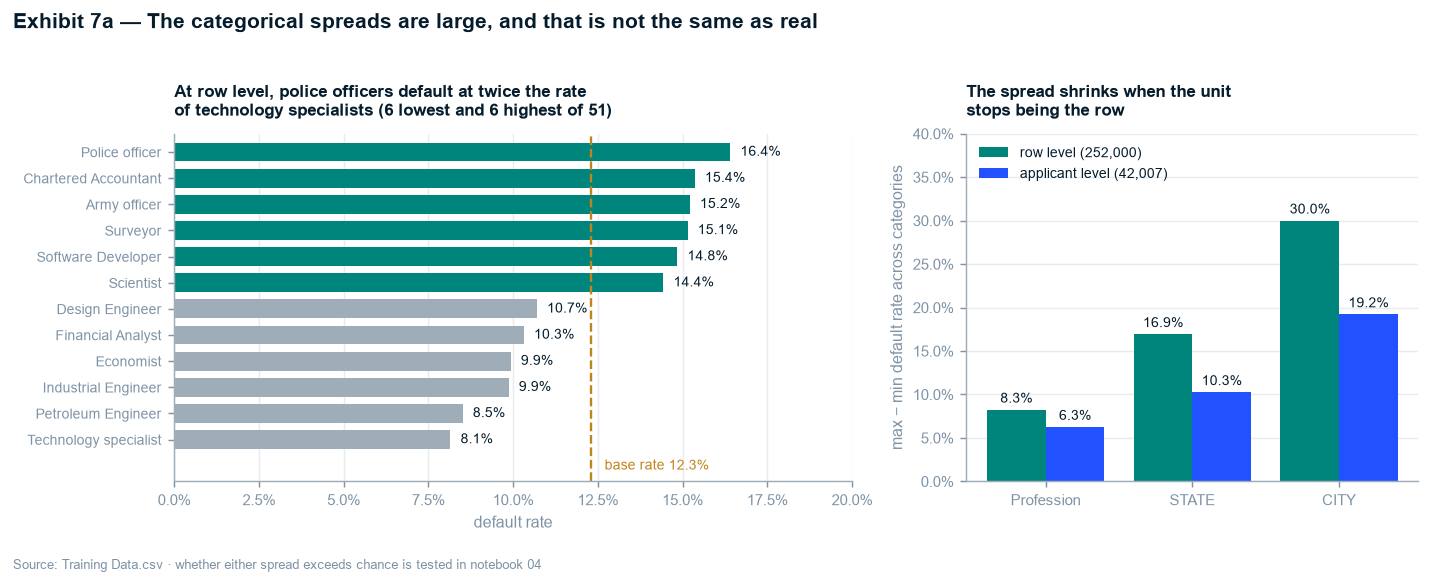

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.0), gridspec_kw={"width_ratios": [1.5, 1]})

p_sorted = prof.sort_values("rate")
ends = pd.concat([p_sorted.head(6), p_sorted.tail(6)])
y = np.arange(len(ends))
ax1.barh(y, ends.rate, color=[C_CONTEXT] * 6 + [C_OPTIMISTIC] * 6, height=0.72)
ax1.axvline(BASE, color=C_REFERENCE, lw=1.3, ls="--")
ax1.text(BASE + .004, -1.15, f"base rate {BASE:.1%}", fontsize=8, color=C_REFERENCE)
for i, v in enumerate(ends.rate):
    ax1.text(v + .003, i, f"{v:.1%}", va="center", fontsize=8, color=NAVY)
ax1.set_yticks(y, [i.replace("_", " ") for i in ends.index], fontsize=8)
ax1.set_ylim(-1.6, len(ends) - 0.3)
ax1.set_xlim(0, 0.20)
ax1.xaxis.set_major_formatter(PCT)
ax1.set_xlabel("default rate")
ax1.grid(axis="x"); ax1.grid(axis="y", visible=False)
ax1.set_title("At row level, police officers default at twice the rate\n"
              "of technology specialists (6 lowest and 6 highest of 51)", fontsize=9.5)

x = np.arange(3)
ax2.bar(x - 0.2, spread.row_spread, 0.4, color=C_OPTIMISTIC, label="row level (252,000)")
ax2.bar(x + 0.2, spread.profile_spread, 0.4, color=C_HONEST, label="applicant level (42,007)")
for i, (a, b) in enumerate(zip(spread.row_spread, spread.profile_spread)):
    ax2.text(i - 0.2, a + .008, f"{a:.1%}", ha="center", fontsize=8, color=NAVY)
    ax2.text(i + 0.2, b + .008, f"{b:.1%}", ha="center", fontsize=8, color=NAVY)
ax2.set_xticks(x, spread.column)
ax2.yaxis.set_major_formatter(PCT)
ax2.set_ylim(0, 0.40)
ax2.set_ylabel("max − min default rate across categories")
ax2.legend(loc="upper left", fontsize=8)
ax2.set_title("The spread shrinks when the unit\nstops being the row", fontsize=9.5)

fig.suptitle("Exhibit 7a — The categorical spreads are large, and that is not the same as real",
             x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=1.03)
finish(ax2, "Training Data.csv", "whether either spread exceeds chance is tested in notebook 04")
plt.tight_layout()
save(fig, "fig_categorical_spread.png")
plt.show()

**So What:** the row-level spreads are wide — 8.3 points across professions, 17.0 across states,
30.0 across cities — and on 252,000 rows a χ² test returns p = 5e-98 for `Profession` and p ≈ 0 for
`CITY`. That is the trap. The median city holds 791 rows but only **22 applicants**; the sample size
that matters is the smaller one.

**Implication:** a significance test is only as valid as its unit of independence. Notebook `04`
runs the permutation at both units and shows that not one of these three columns survives the
correct one.

## 3.4 Branch F — which unit is honest, and what does the answer cost?

The memorisation ceiling is the number the leaderboard is really chasing. Worth seeing plainly.

In [10]:
lookup = rows.groupby("profile_id")[TARGET].transform("mean")
print("if a model simply returned each applicant's own majority label, in-sample:")
print(f"   accuracy {(((lookup >= .5).astype(int)) == rows[TARGET]).mean():.4f}"
      f"   AUC {roc_auc_score(rows[TARGET], lookup):.4f}")
print(f"   vs majority-class accuracy {1 - BASE:.4f}")

print("\nhow much of the file is memorisable?")
print(rows.label_agreement.value_counts().to_frame("rows").assign(
    share=lambda d: (d["rows"] / len(rows)).round(4),
    applicants=rows.groupby("label_agreement")["profile_id"].nunique()).to_string())

print("\ndistribution shape check — is the whole file a draw from a generator?")
print(f"{'column':22s} {'KS D vs uniform':>16s} {'p':>12s}")
for c in NUMERIC:
    x = rows[c].to_numpy(float)
    u = (x - x.min()) / (x.max() - x.min())
    ks = stats.kstest(u, "uniform")
    print(f"{c:22s} {ks.statistic:>16.4f} {ks.pvalue:>12.3g}")

if a model simply returned each applicant's own majority label, in-sample:
   accuracy 0.9355   AUC 0.9776
   vs majority-class accuracy 0.8770

how much of the file is memorisable?
                   rows   share  applicants
label_agreement                            
unanimous_0      173446  0.6883        4817
mixed             42547  0.1688        1183
singleton         36007  0.1429       36007

distribution shape check — is the whole file a draw from a generator?
column                  KS D vs uniform            p


Income                           0.0052     2.32e-06


Age                              0.0203     1.92e-90
Experience                       0.0450            0
CURRENT_JOB_YRS                  0.1384            0
CURRENT_HOUSE_YRS                0.1945            0


In [11]:
summary = pd.DataFrame({
    "cut": ["row level", "applicant level"],
    "n": [len(rows), len(profiles)],
    "Profession spread": [spread.row_spread[0], spread.profile_spread[0]],
    "STATE spread": [spread.row_spread[1], spread.profile_spread[1]],
    "CITY spread": [spread.row_spread[2], spread.profile_spread[2]],
})
print(summary.round(4).to_string(index=False))

kf.update({
    "best_single_feature_auc": float(uni.auc_row.iloc[uni.auc_row.sub(.5).abs().idxmax()]),
    "income_auc": float(uni.loc[uni.feature == "Income", "auc_row"].iloc[0]),
    "experience_auc": float(uni.loc[uni.feature == "Experience", "auc_row"].iloc[0]),
    "max_abs_numeric_corr": float(rows[NUMERIC].corr().abs().where(
        ~np.eye(5, dtype=bool)).max().max()),
    "profession_spread_row": float(spread.row_spread[0]),
    "profession_spread_profile": float(spread.profile_spread[0]),
    "state_spread_row": float(spread.row_spread[1]),
    "state_spread_profile": float(spread.profile_spread[1]),
    "city_spread_row": float(spread.row_spread[2]),
    "city_spread_profile": float(spread.profile_spread[2]),
    "median_applicants_per_city": int(spread.median_applicants_per_cat[2]),
    "median_rows_per_city": int(spread.median_rows_per_cat[2]),
    "owned_default_rate": float(rows.loc[rows.House_Ownership == "owned", TARGET].mean()),
    "rented_default_rate": float(rows.loc[rows.House_Ownership == "rented", TARGET].mean()),
})
(REPORTS / "_key_figures.json").write_text(json.dumps(kf, indent=2))
uni.to_csv(REPORTS / "_univariate.csv", index=False)
spread.to_csv(REPORTS / "_category_spread.csv", index=False)
print(f"\n_key_figures.json now holds {len(kf)} figures")

            cut      n  Profession spread  STATE spread  CITY spread
      row level 252000             0.0826        0.1695       0.3001
applicant level  42007             0.0628        0.1027       0.1923



_key_figures.json now holds 54 figures


## Changelog — what this notebook sent back to Stage 2

Nothing. The reconciliation and the profile index handled every issue EDA surfaced, and no new
defect appeared that notebook `02` had not already logged. The loop `Cleaning ↔ EDA` closed after
one pass, which is worth stating explicitly rather than leaving implied.

## Ghost deck — revised after seeing the data

| Planned | Status after EDA |
|---|---|
| EX 1 replication histogram | **Confirmed**, promoted to hero exhibit |
| EX 6 file-order block chart | **Confirmed**, and stronger than expected — the blocks are identical on every feature |
| EX 3 / EX 4 vocabulary + overlap | **Merged into one exhibit**, because the second defect is what conceals the first |
| "Which attributes associate with risk" | **Answered and null** — largest lift 0.73, best single-feature AUC 0.4698 |
| Categorical drivers | **Deferred to notebook 04** — the row-level spread is large and needs a placebo, not a χ² |

## Stage 3 — Gate Checklist (`DOCS/STRUCTURE.md`)

- [x] **Automated profiling reviewed** — manual describe/skew/KS panel (notebook `01` §1.4 and §3.4
      here); `ydata-profiling` deliberately not added as a dependency
- [x] **Each Stage 0 hypothesis has a corresponding analysis** — branches A–F all covered above
- [x] **Key distributions and relationships visualised and annotated** — 5 exhibits, each with a
      written So What and Implication
- [x] **All chart titles are Action Titles** — every title states the insight, not the content
- [x] **Every finding has a documented "So What?" and "Implication"**
- [x] **Ghost deck updated** — revision table above
- [x] **Data issues discovered during EDA logged and addressed** — none new; loop closed after one pass
- [x] **Preliminary findings documented** — no univariate signal anywhere; the categorical spreads
      are the one open question, and it goes to notebook `04`